# 04 — EDA, Heatmap Korelasi & Insight

**Tujuan:** menjawab pertanyaan analitis dari notebook 01 menggunakan data bersih +
fitur turunan dari notebook 03, lalu menyimpulkan **insight** yang akan diangkat
ke dashboard.

Isi notebook:

1. Distribusi fitur penting
2. Profil audio per genre (bar + radar chart)
3. Tren suara musik per dekade
4. Proporsi lagu explicit
5. Scatter mood (valence × energy)
6. Artis: jumlah lagu vs rata-rata popularity
7. **Heatmap korelasi Pearson & Spearman**
8. Insight (untuk dashboard)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

data = joblib.load("../data/clean/spotify_clean.joblib")
songs, genres_long, artists = data["songs"], data["genres_long"], data["artists"]
print("songs:", songs.shape, "| genres_long:", genres_long.shape, "| artists:", artists.shape)

# Warna konsisten dengan dashboard
BIRU, ORANYE, HIJAU, MERAH, ABU = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#898781"

songs: (1926, 32) | genres_long: (3562, 31) | artists: (835, 11)


## 1. Distribusi fitur penting

Sebelum mencari hubungan antar variabel, kita pahami dulu sebaran tiap fitur.
Perhatikan: **126...** hmm, tepatnya 121 lagu punya `popularity = 0` (data tidak
tersedia) — itulah puncak di ujung kiri histogram popularity.

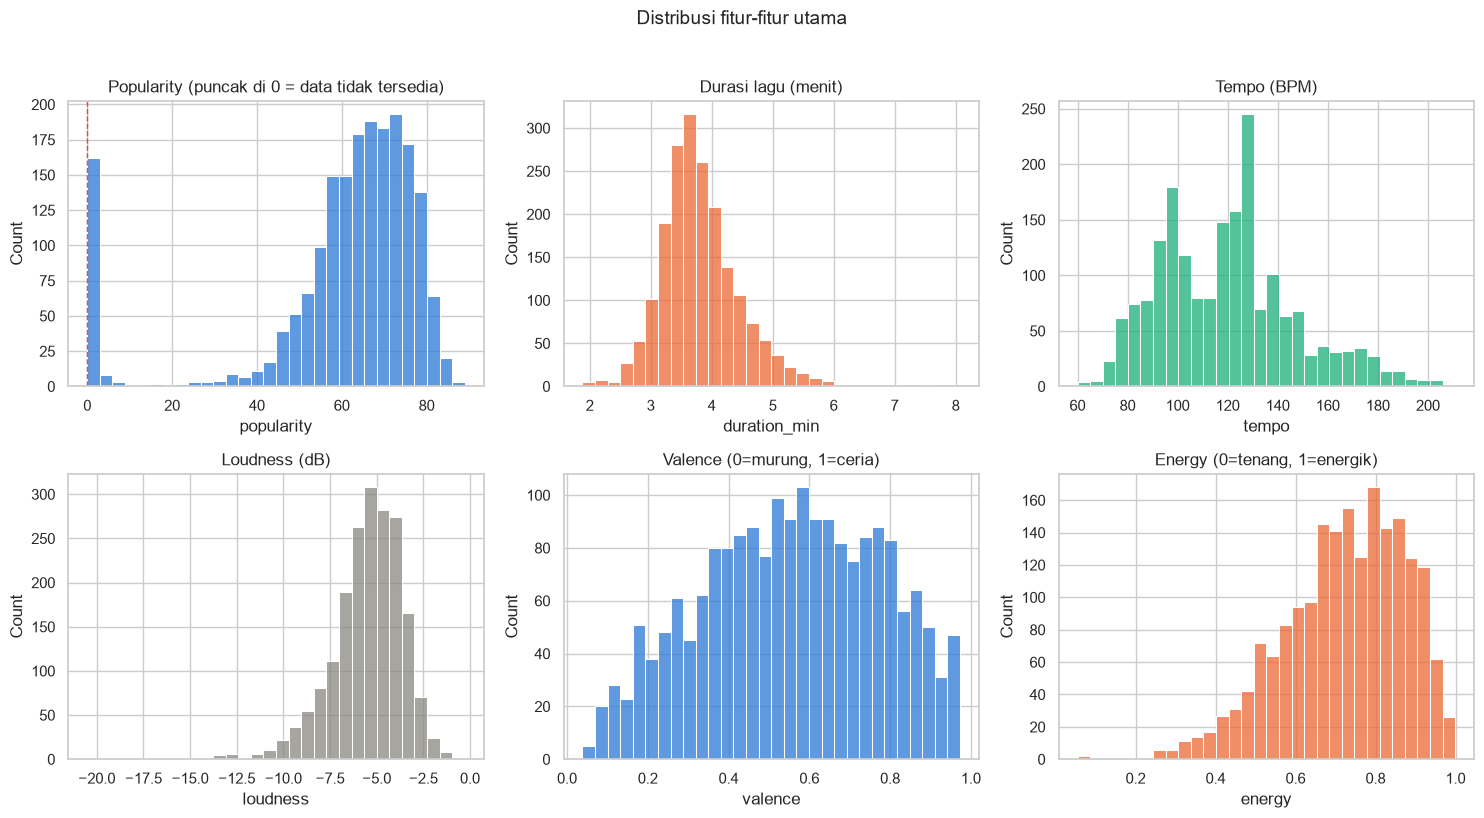

Median durasi: 3.72 menit
Median tempo : 120.0 BPM
Median loudness: -5.3 dB


In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(songs["popularity"], bins=30, ax=axes[0, 0], color=BIRU)
axes[0, 0].set_title("Popularity (puncak di 0 = data tidak tersedia)")
axes[0, 0].axvline(0, color=MERAH, linestyle="--", linewidth=1)

sns.histplot(songs["duration_min"], bins=30, ax=axes[0, 1], color=ORANYE)
axes[0, 1].set_title("Durasi lagu (menit)")

sns.histplot(songs["tempo"], bins=30, ax=axes[0, 2], color=HIJAU)
axes[0, 2].set_title("Tempo (BPM)")

sns.histplot(songs["loudness"], bins=30, ax=axes[1, 0], color=ABU)
axes[1, 0].set_title("Loudness (dB)")

sns.histplot(songs["valence"], bins=30, ax=axes[1, 1], color=BIRU)
axes[1, 1].set_title("Valence (0=murung, 1=ceria)")

sns.histplot(songs["energy"], bins=30, ax=axes[1, 2], color=ORANYE)
axes[1, 2].set_title("Energy (0=tenang, 1=energik)")

plt.suptitle("Distribusi fitur-fitur utama", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

print("Median durasi:", round(songs["duration_min"].median(), 2), "menit")
print("Median tempo :", round(songs["tempo"].median(), 1), "BPM")
print("Median loudness:", round(songs["loudness"].median(), 1), "dB")

## 2. Profil audio per genre

**Hati-hati dobel hitung:** di sini dipakai `primary_genre` (genre pertama tiap
lagu) supaya "jumlah lagu" tetap benar; genre dengan jumlah lagu < 10 dikecualikan
dari perbandingan rata-rata karena representatifnya rendah (baris miring akibat
sedikit sampel).

**Insight yang dicari:** bandingkan rata-rata fitur antar genre besar (pop, hip hop,
Dance/Electronic, rock, metal, R&B).

In [3]:
FITUR = ["danceability", "energy", "valence", "acousticness", "speechiness", "liveness", "instrumentalness"]

profil = (
    songs.groupby("primary_genre")
    .agg(n_lagu=("song", "count"), **{f: (f, "mean") for f in FITUR})
    .query("n_lagu >= 10")
    .sort_values("n_lagu", ascending=False)
)
print(profil[["n_lagu"] + FITUR].round(3).to_string())

                   n_lagu  danceability  energy  valence  acousticness  speechiness  liveness  instrumentalness
primary_genre                                                                                                  
pop                   902         0.649   0.723    0.549         0.146        0.075     0.175             0.016
hip hop               744         0.718   0.700    0.562         0.116        0.152     0.189             0.005
rock                  155         0.545   0.799    0.518         0.067        0.059     0.192             0.028
Dance/Electronic       41         0.685   0.776    0.524         0.068        0.059     0.183             0.104
Unknown                22         0.739   0.739    0.663         0.181        0.065     0.162             0.036
latin                  15         0.735   0.754    0.584         0.237        0.129     0.152             0.001
R&B                    13         0.663   0.688    0.633         0.111        0.121     0.158           

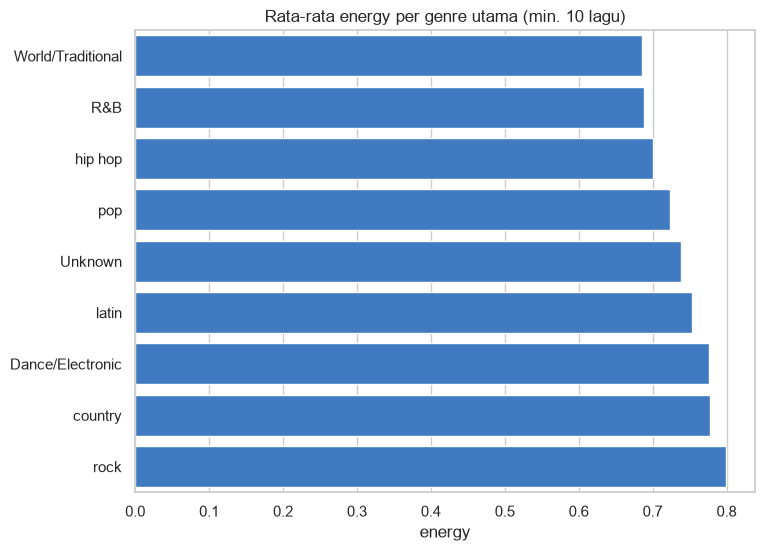

In [4]:
# Bar: rata-rata fitur per genre (urutkan dari yang tertinggi)
fitur_pilih = "energy"
urut = profil.sort_values(fitur_pilih, ascending=True)

plt.figure(figsize=(8, 6))
sns.barplot(x=urut[fitur_pilih], y=urut.index, color=BIRU)
plt.title(f"Rata-rata {fitur_pilih} per genre utama (min. 10 lagu)")
plt.xlabel(fitur_pilih)
plt.ylabel("")
plt.show()

### Radar chart — sidik jari audio tiap genre

Radar menampilkan **bentuk kombinasi** fitur dalam satu gambar — sangat pas untuk
membandingkan jenis musik. Sumbu hanya memakai fitur 0–1 (semua fitur audio Spotify).

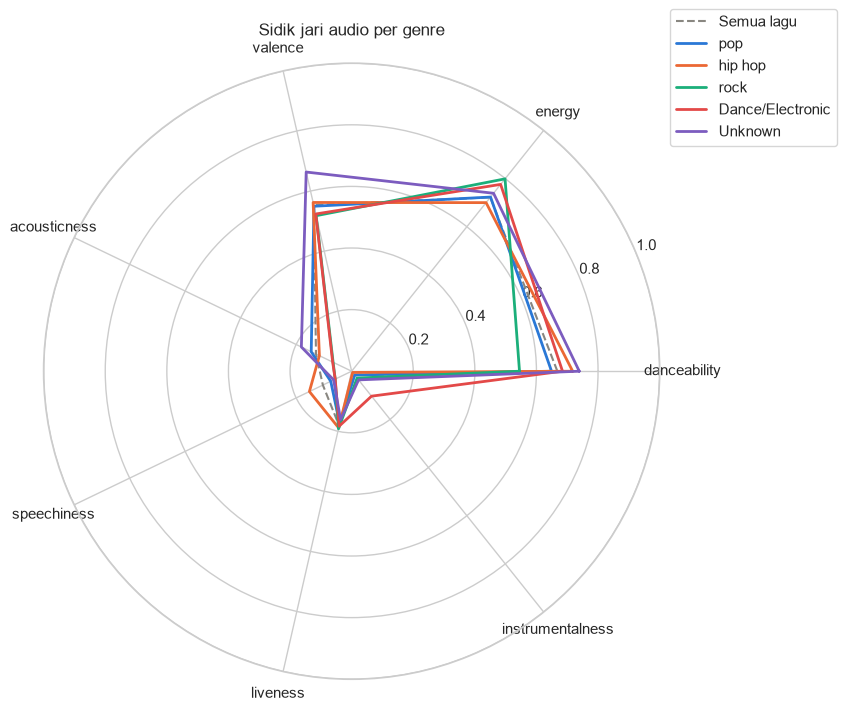

In [5]:
# 5 genre terbesar + garis referensi "semua lagu"
top_genres = profil.sort_values("n_lagu", ascending=False).head(5).index.tolist()

labels = FITUR
sudut = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
sudut += sudut[:1]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

# Referensi: rata-rata semua lagu
all_mean = songs[FITUR].mean().tolist(); all_mean += all_mean[:1]
ax.plot(sudut, all_mean, color=ABU, linewidth=1.5, linestyle="--", label="Semua lagu")

warna_genre = [BIRU, ORANYE, HIJAU, MERAH, "#7c5cbf"]
for warna, genre in zip(warna_genre, top_genres):
    nilai = profil.loc[genre, FITUR].tolist(); nilai += nilai[:1]
    ax.plot(sudut, nilai, color=warna, linewidth=2, label=genre)

ax.set_xticks(sudut[:-1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title("Sidik jari audio per genre", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()

## 3. Tren suara musik per dekade

Pertanyaan klasik dalam industri musik: **apakah lagu makin keras dan makin sedikit
akustik** seiring waktu? Ini bisa diuji langsung dari data loudness, energy, dan
acousticness per dekade.

Catatan: 2020an hanya punya 3 lagu di dataset ini — dekade itu hampir tidak
informatif, jadi visual fokus ke tiga dekade penuh.

        n_lagu  loudness  energy  acousticness  duration_min  valence
decade                                                               
1990an      39    -6.073   0.731         0.149         4.207    0.573
2000an     904    -5.543   0.731         0.124         3.986    0.594
2010an     980    -5.459   0.713         0.132         3.634    0.515
2020an       3    -4.925   0.785         0.147         3.620    0.540


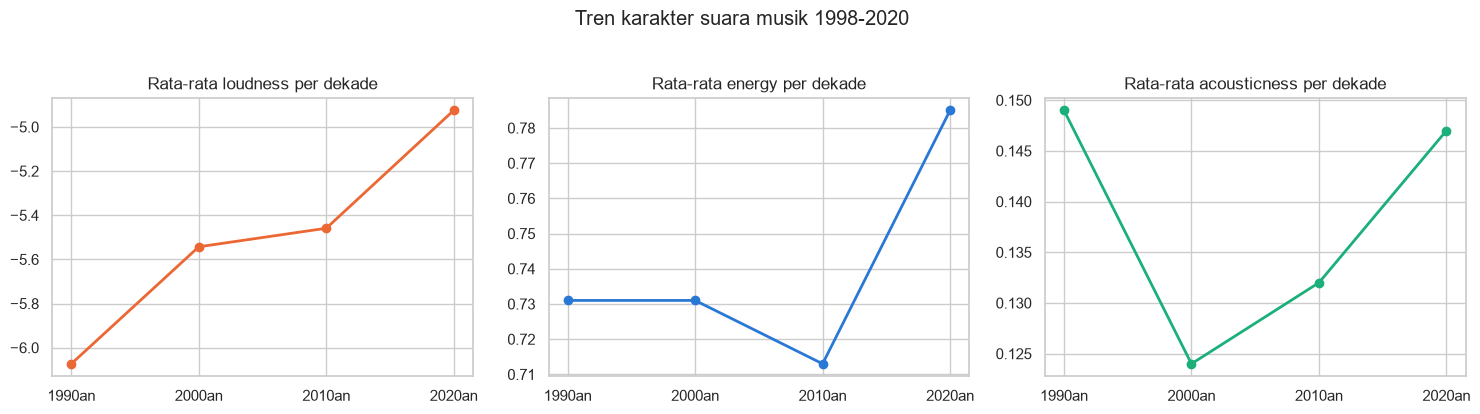

In [6]:
tren = songs.groupby("decade", observed=True).agg(
    n_lagu=("song", "count"),
    loudness=("loudness", "mean"),
    energy=("energy", "mean"),
    acousticness=("acousticness", "mean"),
    duration_min=("duration_min", "mean"),
    valence=("valence", "mean"),
).round(3)
print(tren.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kolom, warna in zip(axes, ["loudness", "energy", "acousticness"], [ORANYE, BIRU, HIJAU]):
    ax.plot(tren.index.astype(str), tren[kolom], marker="o", color=warna, linewidth=2)
    ax.set_title(f"Rata-rata {kolom} per dekade")
    ax.set_xlabel("")
plt.suptitle("Tren karakter suara musik 1998-2020", y=1.03)
plt.tight_layout()
plt.show()

## 4. Proporsi lagu explicit

Apakah lagu explicit makin umum? Dan genre mana yang paling banyak explicit?

Proporsi explicit per dekade:
decade
1990an    0.231
2000an    0.263
2010an    0.290
2020an    0.667

Proporsi explicit per genre (min. 10 lagu):
                    mean  count
primary_genre                  
hip hop            0.551    744
latin              0.200     15
Dance/Electronic   0.171     41
R&B                0.154     13
pop                0.102    902
World/Traditional  0.100     10
Unknown            0.091     22
rock               0.084    155
country            0.000     10


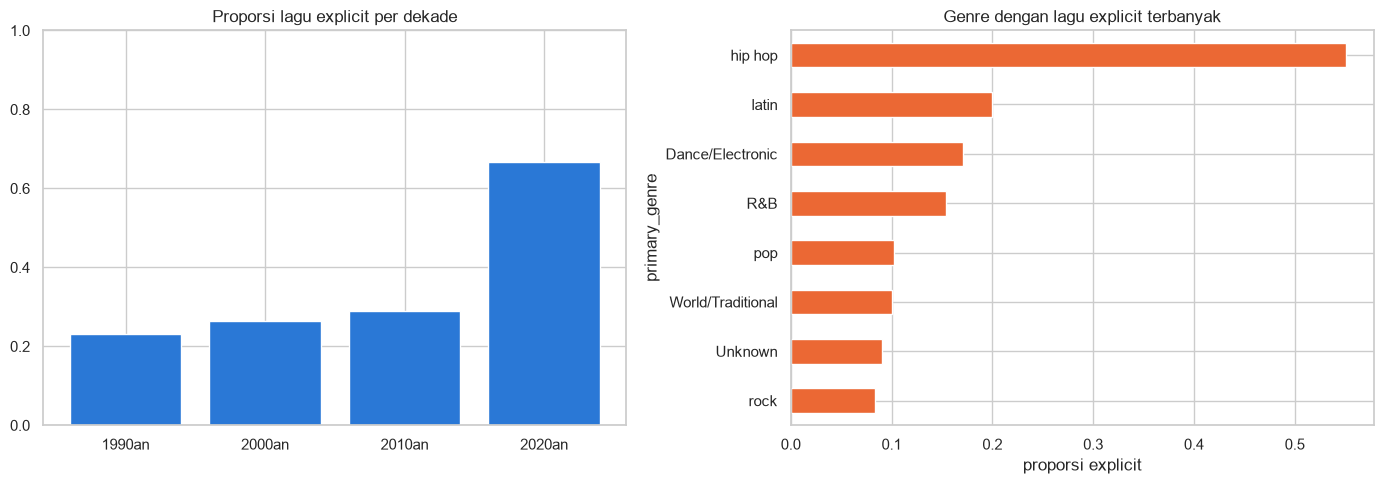

In [7]:
eksplisit_dekade = songs.groupby("decade", observed=True)["explicit"].mean()
print("Proporsi explicit per dekade:")
print(eksplisit_dekade.round(3).to_string())

eksplisit_genre = songs.groupby("primary_genre")["explicit"].agg(["mean", "count"]).query("count >= 10")
eksplisit_genre = eksplisit_genre.sort_values("mean", ascending=False)
print("\nProporsi explicit per genre (min. 10 lagu):")
print(eksplisit_genre.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(eksplisit_dekade.index.astype(str), eksplisit_dekade.values, color=BIRU)
axes[0].set_title("Proporsi lagu explicit per dekade")
axes[0].set_ylim(0, 1)

eksplisit_genre.head(8).plot.barh(y="mean", ax=axes[1], color=ORANYE, legend=False)
axes[1].set_title("Genre dengan lagu explicit terbanyak")
axes[1].invert_yaxis()
axes[1].set_xlabel("proporsi explicit")
plt.tight_layout()
plt.show()

## 5. Scatter mood: valence × energy

Ini visual inti konsep `mood`. Setiap titik = satu lagu; warna = popularity (semakin
terang makin populer). Garis putus-putus di 0.5 memisahkan keempat kuadran mood.

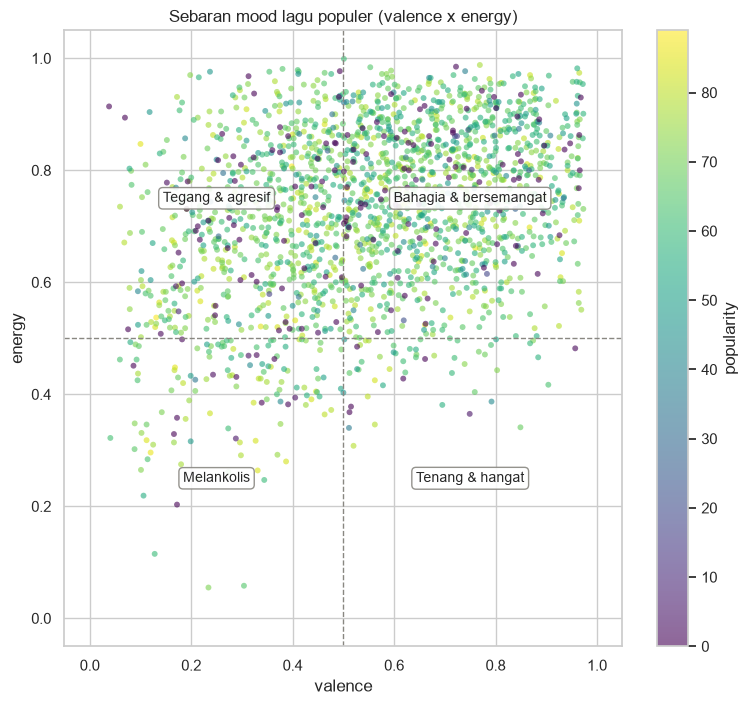

Jumlah lagu per mood:
mood
Bahagia & bersemangat    1099
Tegang & agresif          653
Tenang & hangat            52
Melankolis                122


In [8]:
plt.figure(figsize=(9, 8))
scatter = plt.scatter(
    songs["valence"], songs["energy"],
    c=songs["popularity"], cmap="viridis", alpha=0.6, s=18, edgecolor="none",
)
plt.colorbar(scatter, label="popularity")
plt.axhline(0.5, color=ABU, linestyle="--", linewidth=1)
plt.axvline(0.5, color=ABU, linestyle="--", linewidth=1)
plt.xlabel("valence"); plt.ylabel("energy")
plt.xlim(-0.05, 1.05); plt.ylim(-0.05, 1.05)

# Label keempat kuadran
for x, y, teks in [(0.75, 0.75, "Bahagia & bersemangat"), (0.75, 0.25, "Tenang & hangat"),
                   (0.25, 0.75, "Tegang & agresif"), (0.25, 0.25, "Melankolis")]:
    plt.text(x, y, teks, ha="center", va="center", fontsize=10,
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=ABU, alpha=0.9))

plt.title("Sebaran mood lagu populer (valence x energy)")
plt.show()

print("Jumlah lagu per mood:")
print(songs["mood"].value_counts().sort_index().to_string())

## 6. Artis: banyak lagu vs rata-rata popularity

Apakah artis yang sering muncul di daftar juga punya rata-rata popularity tinggi?
Hanya artis dengan >= 3 lagu ditampilkan supaya rata-ratanya stabil.

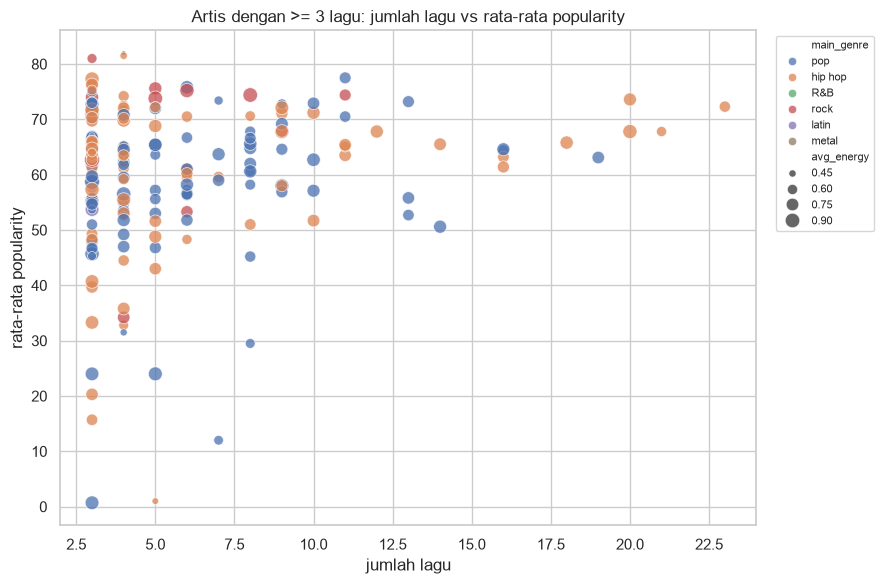

Artis paling sering muncul:
        artist  n_songs  avg_popularity  best_popularity main_genre
       Rihanna       23            72.3               81    hip hop
         Drake       21            67.8               84    hip hop
 Calvin Harris       20            67.8               81    hip hop
        Eminem       20            73.6               87    hip hop
Britney Spears       19            63.1               81        pop
  David Guetta       18            65.8               79    hip hop
       Beyoncé       16            64.4               76        pop
   Chris Brown       16            63.2               74    hip hop
    Kanye West       16            61.4               82    hip hop
    Katy Perry       16            64.6               74        pop


In [9]:
artis_aktif = artists.query("n_songs >= 3")

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=artis_aktif, x="n_songs", y="avg_popularity",
    size="avg_energy", hue="main_genre", sizes=(10, 120), alpha=0.75, palette="deep",
)
plt.title("Artis dengan >= 3 lagu: jumlah lagu vs rata-rata popularity")
plt.xlabel("jumlah lagu"); plt.ylabel("rata-rata popularity")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print("Artis paling sering muncul:")
print(artists.nlargest(10, "n_songs")[["artist", "n_songs", "avg_popularity", "best_popularity", "main_genre"]].to_string(index=False))

## 7. Heatmap korelasi — Pearson & Spearman

**Kolom yang dipakai:** fitur audio (0–1), `loudness`, `tempo`, `duration_min`,
`popularity`, dan `explicit_int`.

**Kenapa dua metode?**
- **Pearson** mengukur hubungan linear — cocok kalau keduanya bergerak lurus.
- **Spearman** bekerja pada peringkat — jauh lebih tahan terhadap outlier dan
  distribusi miring (dan data kita banyak yang miring: popularity, durasi).

**Catatan penting:**
- `key` dan `mode` sengaja **tidak** dimasukkan: keduanya kategorikal (nada &
  mayor/minor), korelasi angka di atasnya menyesatkan.
- 121 lagu punya popularity 0 (tanpa data) — puncak ini sedikit melemahkan
  korelasi yang melibatkan popularity.
- **Korelasi bukan sebab-akibat.** Lagu cepat = lagu populer? Tidak otomatis.

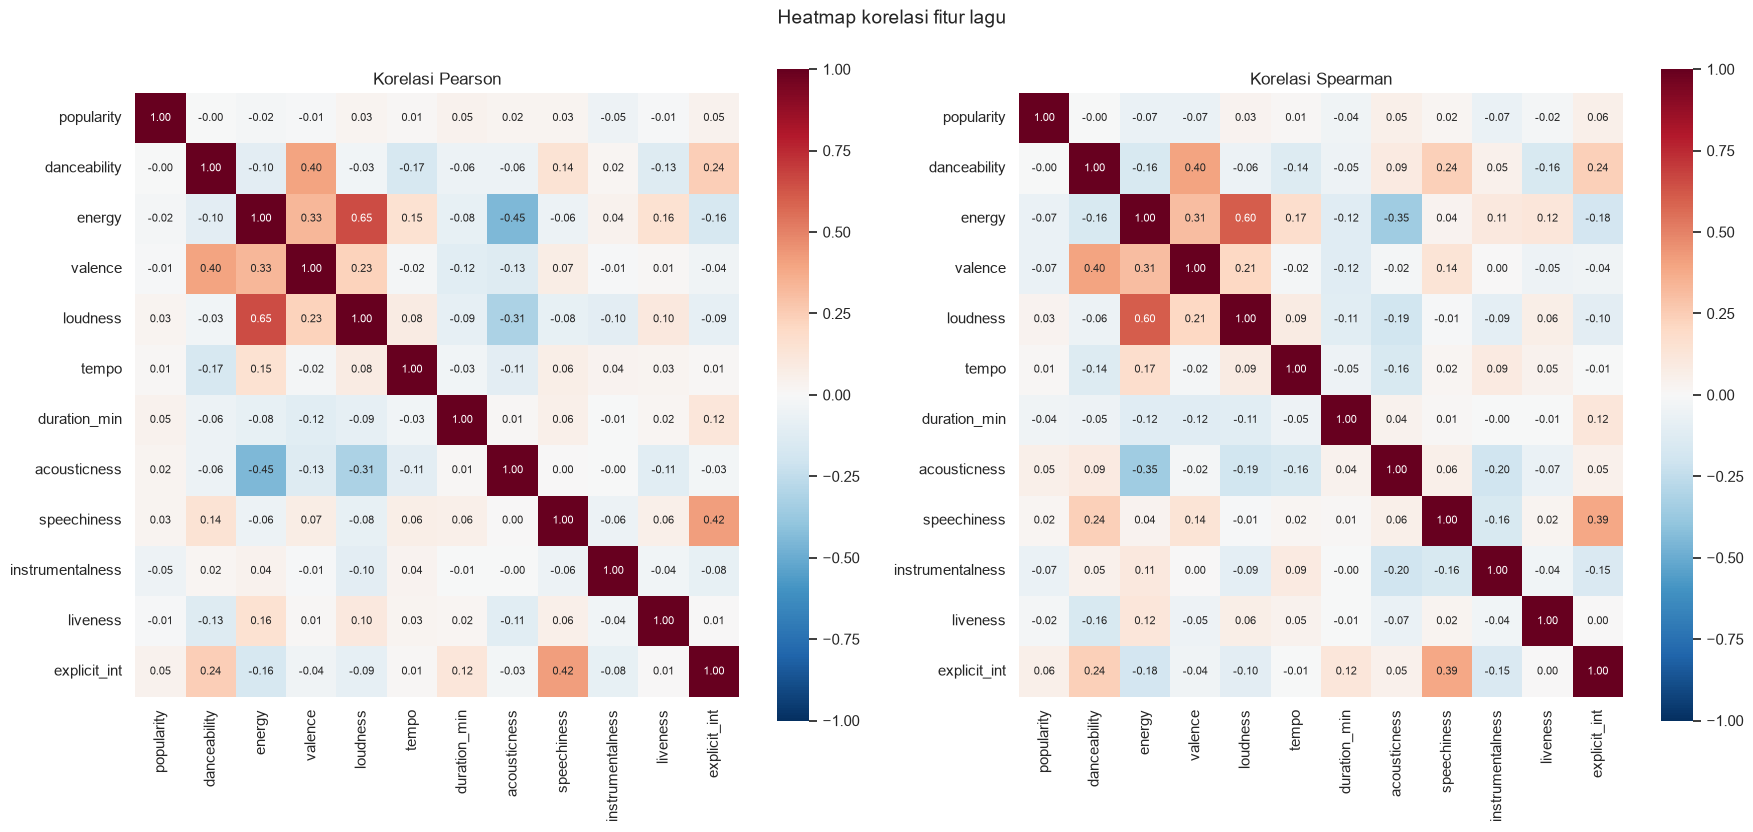

In [10]:
KOLOM_KORELASI = ["popularity", "danceability", "energy", "valence", "loudness",
                 "tempo", "duration_min", "acousticness", "speechiness",
                 "instrumentalness", "liveness", "explicit_int"]

corr_p = songs[KOLOM_KORELASI].corr(method="pearson")
corr_s = songs[KOLOM_KORELASI].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, corr, metode in [(axes[0], corr_p, "Pearson"), (axes[1], corr_s, "Spearman")]:
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, ax=ax,
                annot_kws={"size": 8})
    ax.set_title(f"Korelasi {metode}")
plt.suptitle("Heatmap korelasi fitur lagu", y=1.00, fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
def pasangan_terkuat(corr, n=5):
    mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
    tri = corr.where(mask).stack().abs().sort_values(ascending=False)
    return tri.head(n)

print("5 pasangan korelasi terkuat (Pearson, |r|):")
print(pasangan_terkuat(corr_p).round(3).to_string())
print("\n5 pasangan korelasi terkuat (Spearman, |rho|):")
print(pasangan_terkuat(corr_s).round(3).to_string())

5 pasangan korelasi terkuat (Pearson, |r|):
energy        loudness        0.651
              acousticness    0.449
speechiness   explicit_int    0.415
danceability  valence         0.404
energy        valence         0.333

5 pasangan korelasi terkuat (Spearman, |rho|):
energy        loudness        0.602
danceability  valence         0.400
speechiness   explicit_int    0.390
energy        acousticness    0.354
              valence         0.306


## 8. Angka kunci (untuk insight & dashboard)

Ringkasan otomatis angka-angka yang dikutip di bagian insight.

In [12]:
print("=== ANGKA KUNCI ===")
print(f"Total lagu (setelah cleaning)   : {len(songs)}")
print(f"Total artis                     : {songs['artist'].nunique()}")
print(f"Tahun                          : {songs['year'].min()}-{songs['year'].max()}")
print(f"Rata-rata popularity (data ada)  : {songs.loc[~songs['is_popularity_missing'], 'popularity'].mean():.1f}")
print(f"Popularity tidak tersedia        : {songs['is_popularity_missing'].sum()} ({songs['is_popularity_missing'].mean():.1%})")
print(f"Median durasi                   : {songs['duration_min'].median():.2f} menit")
print(f"Median tempo                    : {songs['tempo'].median():.0f} BPM")
print(f"Proporsi Major                  : {(songs['mode']==1).mean():.1%}")
print(f"Proporsi explicit               : {songs['explicit'].mean():.1%}")
print()
print("Mood:")
print(songs["mood"].value_counts(normalize=True).sort_index().round(3).to_string())
print()
print("Korelasi dengan popularity (Spearman):")
print(corr_s["popularity"].drop("popularity").sort_values(key=abs, ascending=False).round(3).to_string())
print()
print("Genre terbesar (primary_genre):")
print(songs["primary_genre"].value_counts().head(6).to_string())

=== ANGKA KUNCI ===
Total lagu (setelah cleaning)   : 1926
Total artis                     : 835
Tahun                          : 1998-2020
Rata-rata popularity (data ada)  : 63.8
Popularity tidak tersedia        : 121 (6.3%)
Median durasi                   : 3.72 menit
Median tempo                    : 120 BPM
Proporsi Major                  : 55.3%
Proporsi explicit               : 27.7%

Mood:
mood
Bahagia & bersemangat    0.571
Tegang & agresif         0.339
Tenang & hangat          0.027
Melankolis               0.063

Korelasi dengan popularity (Spearman):
energy             -0.070
valence            -0.070
instrumentalness   -0.066
explicit_int        0.060
acousticness        0.055
duration_min       -0.044
loudness            0.032
speechiness         0.017
liveness           -0.017
tempo               0.014
danceability       -0.002

Genre terbesar (primary_genre):
primary_genre
pop                 902
hip hop             744
rock                155
Dance/Electronic     41
Un

## 9. Insight untuk dashboard

Temuan ini (angka dari eksekusi notebook) yang diangkat ke dashboard:

**1. Tidak ada "formula ajaib" untuk populer.** Semua fitur audio berkorelasi
sangat lemah dengan popularity — yang terkuat pun hanya |rho| = 0.07
(energy & valence). Karakter audio hampir tidak menjelaskan kepopuleran; faktor
non-audio (artis, promosi, viral) jauh lebih berperan. Insight jujur yang menarik
untuk ditunjukkan di tab Korelasi.

**2. Lagu keras = lagu nyaring.** Pasangan berkorelasi terkuat: energy ↔ loudness
(Pearson r = 0.65, Spearman 0.60) — ciri khas era "loudness war".

**3. Musik chart makin pendek dan sedikit lebih keras.** 1990an → 2010an:
loudness rata-rata naik -6.07 → -5.46 dB; durasi turun 4.21 → 3.63 menit (-14%);
acousticness turun 14.9% → 13.2%. Sejalan dengan era streaming: lagu pendek lebih
mudah diputar berulang.

**4. Dua genre menutupi 85% data.** pop (902 lagu) + hip hop (744) dari 1.926
lagu. Genre kecil (< 15 lagu) terlalu sedikit untuk dibandingkan — diberi penanda
"sedikit lagu" di dashboard.

**5. Hip hop jelas paling eksplisit: 55%** lagu (vs rock 8%, pop 10%).
Secara umum 27.7% lagu eksplisit, dan proporsinya naik pelan tiap dekade
(23% → 29%).

**6. Musik chart rata-rata "ceria dan bersemangat".** 57% lagu berada di kuadran
Bahagia & bersemangat (valence & energy tinggi), 34% Tegang & agresif. Kuadran
Tenang & hangat paling jarang (2.7%).

**7. Banyak bicara → eksplisit.** speechiness berkorelasi dengan explicit
(Spearman rho = 0.39) — konsisten dengan dominasi rap/hip hop di lagu eksplisit.

**8. Artis dengan lagu terbanyak belum tentu yang terpopuler.** Rihanna paling
sering muncul (23 lagu), tetapi rata-rata popularity tertinggi di antara top-10
adalah Eminem (73.6 dari 20 lagu); Britney Spears punya 19 lagu dengan rata-rata
hanya 63.1.

> Untuk dashboard, insight **1, 3, 4, 5** adalah yang paling komunikatif.

## 10. Dari angka ke cerita — cara menceritakan temuan ini

Ini inti pekerjaan data analyst: **temuan belum berarti apa-apa sebelum orang lain
memahaminya**. Pola yang dipakai seluruh project ini:

> ### Hook → Angka → Makna → Rekomendasi

**1. Hook** — satu kalimat yang membuat orang berhenti scrolling.
Contoh: *"Ternyata nggak ada 'formula suara' untuk bikin lagu hits."*

**2. Angka** — bukti pendukung, biasanya 1–2 angka saja (bukan semua tabel).
Contoh: *"korelasi terkuat fitur audio dengan popularity cuma 0.07 — praktis nol."*

**3. Makna** — terjemahan angka ke bahasa manusia.
Contoh: *"Berarti yang membuat lagu populer bukan suaranya, tapi hal di luar audio:
siapa penyanyinya, kapan rilis, dan seberapa viral lagunya."*

**4. Rekomendasi** — apa yang harus dilakukan pembaca dengan temuan ini.
Contoh: *"Kalau kamu penyanyi independen, jangan cuma mengandalkan 'bikin sound
hip'; promosi dan distribusi tetap yang paling menentukan."*

**Contoh naskah 30 detik (latihan presentasi):**

> "Kami analisis 1.926 lagu populer dari 835 artis. Temuan paling menarik: **nggak ada
> formula ajaib** — dari 11 fitur audio, yang paling dekat kaitannya dengan
> popularity hanya 0.07 dari skala 1. Yang ternyata menarik adalah pola waktu:
> lagu makin **pendek** (4,2 → 3,6 menit) dan sedikit lebih **keras**, dan 57%
> lagu bernuansa **bahagia-energik**. Dashboard di folder `app/` memungkinkan tim
> mengecek tren ini sendiri per genre dan per dekade."

**Hubungan insight dengan dashboard (tempat orang mengecek ceritamu):**

| Insight | Di dashboard |
|---|---|
| Tidak ada formula ajaib | Tab **Korelasi** (heatmap + pasangan terkuat) |
| Tren pendek & keras | Tab **Ringkasan** (lagu per tahun) + notebook ini |
| Pop vs hip hop, explicit | Tab **Genre & audio** (detail per genre) & **Artis & lagu** |
| Mood dominan | Tab **Ringkasan** (sebaran mood) |
| Artis & lagu top | Tab **Artis & lagu** |

**Jangan lakukan saat storytelling data:**

| Jangan | Lakukan |
|---|---|
| Bangga menunjukkan 12 grafik sekaligus | 1 grafik = 1 pesan |
| "Korelasi r = 0.65, jadi energy menyebabkan loudness" | "Energy dan loudness sering berjalan bersama" |
| Menyembunyikan bahwa 121 lagu popularity-nya kosong | Sebutkan keterbatasan data (lihat README) |
| Menutup dengan "insightnya banyak" | Tutup dengan 1 rekomendasi yang bisa dieksekusi |